# Four-wavelength BB84 with Qiskit Aer

Adapted from your `bb84_simulation.ipynb`. Alice, Eve, Bob, sifting and public error sampling are preserved. NumPy state-vector measurement is replaced by **actual Qiskit Aer circuit shots**.

**Run:** install Python 3.11+; in your notebook environment run `%pip install qiskit qiskit-aer numpy pandas matplotlib`, restart the kernel, then Run All. This notebook is self-contained: it does not require the companion Python package, an IBM account, or quantum hardware.

**Scope:** four independent logical wavelength modes, with attack and background-error settings per mode. The labels are illustrative; this notebook does not model optical multiplexers, Raman scattering, decoy pulses, photon-number splitting, or secure key rate. Those belong to the project's separate optical model.

**Security:** unrevealed sifted bits are raw key material. There is no error correction, privacy amplification, authenticated classical channel or finite-key proof. An 11% line is an illustrative operating threshold, not proof that a key is secure. High QBER does not uniquely identify an attacker.


## 1. Qiskit circuit engine

Each independent pulse uses one qubit. Alice applies X for bit 1 and H for the X basis. If Eve intercepts, she rotates into her basis, measures, and rotates back to resend the collapsed state. Bob rotates into his basis and measures.

Equivalent preparation/basis combinations are grouped for speed. Every used outcome is still an Aer shot, assigned back to its original pulse index. Padding shots are discarded. Wavelengths are separate sessions, not entangled registers. A symmetric Y channel implements the original notebook's basis-independent bit-error probability.


In [1]:
"""All detected BB84 measurement outcomes are sampled by Qiskit Aer.

Equivalent independent preparations are grouped into circuits to avoid building
one circuit per pulse. Each circuit shot still represents one detected pulse.
"""
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import pauli_error


class BB84Engine:
    def __init__(self, seed=7):
        self.rng = np.random.default_rng(seed)
        self.backend = AerSimulator(method="stabilizer", max_parallel_threads=1)
        self.shots_executed = 0

    @staticmethod
    def circuit(bit, alice_basis, bob_basis, error_probability=0, eve_basis=None):
        qc = QuantumCircuit(1, 2 if eve_basis is not None else 1)
        if bit:
            qc.x(0)
        if alice_basis:
            qc.h(0)
        if eve_basis is not None:
            if eve_basis:
                qc.h(0)
            qc.measure(0, 0)  # collapse, then resend the measured state
            if eve_basis:
                qc.h(0)
        if error_probability:
            # A Y error flips the measurement outcome in both BB84 bases.
            qc.append(pauli_error([("Y", error_probability),
                                   ("I", 1-error_probability)]).to_instruction(), [0])
        if bob_basis:
            qc.h(0)
        qc.measure(0, qc.num_clbits - 1)
        return qc

    def measure(self, detections, error_probability, intercept_fraction=0.0):
        if detections < 0 or not 0 <= error_probability <= 0.5 or not 0 <= intercept_fraction <= 1:
            raise ValueError("Invalid BB84 sampling parameters")
        if not detections:
            return {"sifted": 0, "errors": 0, "detections": 0}
        circuits, groups = [], []
        # Random bit, Alice basis, Bob basis, Eve participation and Eve basis.
        specs, weights = [], []
        for bit in (0, 1):
            for a in (0, 1):
                for b in (0, 1):
                    specs.append((bit, a, b, None))
                    weights.append((1-intercept_fraction)/8)
                    for eve in (0, 1):
                        specs.append((bit, a, b, eve))
                        weights.append(intercept_fraction/16)
        counts = self.rng.multinomial(int(detections), weights)
        for spec, count in zip(specs, counts):
            if count:
                bit, a, b, eve = spec
                circuits.append(self.circuit(bit, a, b, error_probability, eve))
                groups.append((bit, a, b, int(count)))
        # Aer has a single shots count per job. Unused padding shots are ignored.
        shots = max(g[3] for g in groups)
        result = self.backend.run(circuits, shots=shots, memory=True,
                  seed_simulator=int(self.rng.integers(1, 2**31-1))).result()
        self.shots_executed += shots * len(circuits)
        sifted = errors = 0
        for i, (bit, a, b, count) in enumerate(groups):
            if a == b:
                outcomes = result.get_memory(i)[:count]
                sifted += count
                errors += sum(int(outcome.replace(" ", "")[0]) != bit for outcome in outcomes)
        return {"sifted": sifted, "errors": errors, "detections": int(detections)}

from math import sqrt
def wilson(errors, n, z=3.0):
    if not n:
        return 0.0, 1.0
    p = errors/n
    denom = 1+z*z/n
    centre = (p+z*z/(2*n))/denom
    radius = z*sqrt(p*(1-p)/n+z*z/(4*n*n))/denom
    return max(0.0, centre-radius), min(1.0, centre+radius)




## 2. Your BB84 function, adapted to Qiskit

The return fields remain familiar. Empty samples are handled explicitly; lost pulses are excluded rather than converted into zero bits. The reported QBER uses only the publicly revealed sample. The 95% Wilson interval quantifies sampling uncertainty, not full QKD security.


In [2]:
"""Qiskit adaptation of the supplied bb84_simulation.ipynb.

Keeps explicit bit arrays and a revealed random test sample. No error correction
or privacy amplification: remaining arrays are raw key material, not secure keys.
Wavelengths are independently encoded logical modes, not extra entangled qubits.
"""
from dataclasses import dataclass
import numpy as np


def bb84(n_qubits=2000, eve_fraction=0.0, channel_noise=0.0,
         sample_fraction=0.25, qber_threshold=0.11, seed=42,
         detection_probability=1.0):
    if not isinstance(n_qubits, (int, np.integer)) or n_qubits < 0:
        raise ValueError("n_qubits must be a nonnegative integer")
    if not 0 <= eve_fraction <= 1 or not 0 <= channel_noise <= 0.5:
        raise ValueError("Invalid Eve fraction or channel noise")
    if not 0 < sample_fraction <= 1 or not 0 <= detection_probability <= 1:
        raise ValueError("Invalid sample fraction or detection probability")
    if not 0 <= qber_threshold <= 0.5:
        raise ValueError("Invalid QBER threshold")
    rng = np.random.default_rng(seed)
    alice_bits = rng.integers(0, 2, n_qubits)
    alice_bases = rng.integers(0, 2, n_qubits)
    bob_bases = rng.integers(0, 2, n_qubits)
    intercepted = rng.random(n_qubits) < eve_fraction
    eve_bases = rng.integers(0, 2, n_qubits)
    # Basis-independent erasure; discarded pulses never become bit zero.
    detected = rng.random(n_qubits) < detection_probability
    bob_bits = np.full(n_qubits, -1, dtype=int)
    engine = BB84Engine(seed)
    circuits, groups = [], []
    for bit in (0, 1):
        for a in (0, 1):
            for b in (0, 1):
                for eve in (None, 0, 1):
                    selection = detected & (alice_bits == bit) & (alice_bases == a) & (bob_bases == b)
                    selection &= (~intercepted if eve is None else intercepted & (eve_bases == eve))
                    indices = np.flatnonzero(selection)
                    if len(indices):
                        circuits.append(engine.circuit(bit, a, b, channel_noise, eve))
                        groups.append(indices)
    shots_executed = 0
    if circuits:
        shots = max(map(len, groups))
        result = engine.backend.run(circuits, shots=shots, memory=True,
                    seed_simulator=int(rng.integers(1, 2**31-1))).result()
        shots_executed = shots*len(circuits)
        for i, indices in enumerate(groups):
            # Qiskit prints high-index classical bits first; Bob is the last
            # measured classical bit, so his outcome is the leftmost character.
            bob_bits[indices] = [int(x.replace(" ", "")[0])
                                for x in result.get_memory(i)[:len(indices)]]
    keep = detected & (alice_bases == bob_bases)
    alice_sifted, bob_sifted = alice_bits[keep], bob_bits[keep]
    n_sifted = len(alice_sifted)
    n_sample = min(n_sifted, max(1, int(sample_fraction*n_sifted))) if n_sifted else 0
    sample_idx = rng.choice(n_sifted, n_sample, replace=False)
    errors = int(np.count_nonzero(alice_sifted[sample_idx] != bob_sifted[sample_idx]))
    qber = errors/n_sample if n_sample else None
    mask = np.ones(n_sifted, dtype=bool)
    mask[sample_idx] = False
    alice_key, bob_key = alice_sifted[mask], bob_sifted[mask]
    aborted = qber is None or qber > qber_threshold
    return {
        "n_sent": n_qubits, "n_detected": int(detected.sum()), "n_sifted": n_sifted,
        "n_sample": n_sample, "sample_errors": errors, "qber": qber,
        "qber_ci": wilson(errors, n_sample, z=1.96), "aborted": aborted,
        "status": "insufficient_data" if qber is None else "abort" if aborted else "below_demo_threshold",
        "alice_key": alice_key, "bob_key": bob_key,
        "keys_match": bool(n_sifted and np.array_equal(alice_key, bob_key)),
        "key_error_rate": float(np.mean(alice_key != bob_key)) if len(alice_key) else None,
        "sifted_errors": int(np.count_nonzero(alice_sifted != bob_sifted)),
        "aer_shots": shots_executed,
    }




In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

checks = []
for name, fraction in [('No Eve', 0.0), ('Eve intercepts all', 1.0)]:
    result = bb84(n_qubits=20000, eve_fraction=fraction, seed=42)
    checks.append({'scenario': name, 'sent': result['n_sent'],
                   'sifted': result['n_sifted'], 'sample': result['n_sample'],
                   'sample_errors': result['sample_errors'], 'qber': result['qber'],
                   'raw_keys_match': result['keys_match'], 'status': result['status']})
print(pd.DataFrame(checks).to_string(index=False))
assert checks[0]['qber'] == 0
assert 0.20 < checks[1]['qber'] < 0.30


          scenario  sent  sifted  sample  sample_errors     qber  raw_keys_match               status
            No Eve 20000   10104    2526              0 0.000000            True below_demo_threshold
Eve intercepts all 20000   10104    2526            620 0.245447           False                abort


## 3. Inspect the intercept-resend circuit

Example: Alice sends bit 1 in Z; Eve measures in X; Bob measures in Z. Classical bit c0 records Eve, c1 records Bob. Bob is the leftmost bit of Qiskit memory strings.


In [4]:
print(BB84Engine.circuit(bit=1, alice_basis=0, bob_basis=0, eve_basis=1).draw(output="text"))


     ┌───┐┌───┐┌─┐┌───┐┌─┐
  q: ┤ X ├┤ H ├┤M├┤ H ├┤M├
     └───┘└───┘└╥┘└───┘└╥┘
c: 2/═══════════╩═══════╩═
                0       1 


## 4. Validate partial interception

In the ideal, lossless model, expected sifted QBER is `f / 4`, where `f` is Eve's interception fraction. With independent symmetric channel bit errors `e`, it becomes `e + (f/4)*(1-2e)`; simply adding the two error rates double-counts cases where the flips cancel.


 fraction   qber    low   high  theory
      0.0 0.0000 0.0000 0.0015    0.00
      0.2 0.0513 0.0433 0.0607    0.05
      0.4 0.1055 0.0941 0.1182    0.10
      0.6 0.1554 0.1418 0.1701    0.15
      0.8 0.2063 0.1908 0.2226    0.20
      1.0 0.2617 0.2449 0.2794    0.25


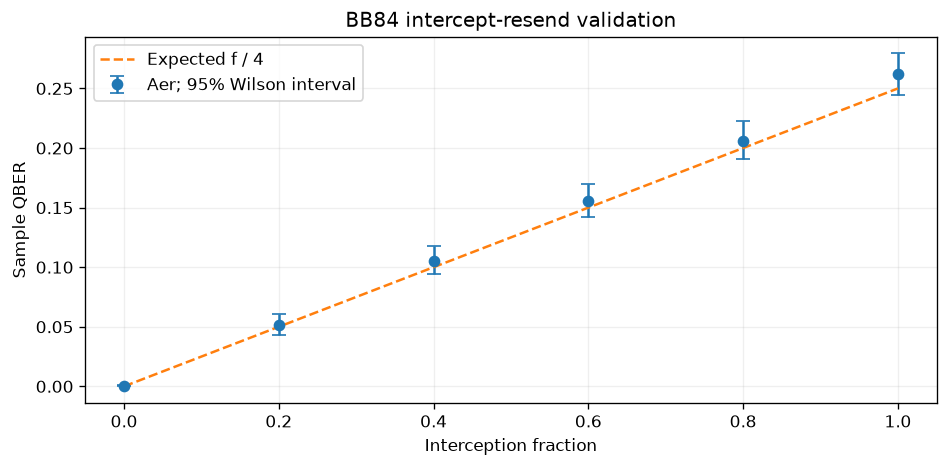

In [5]:
sweep = []
for j, f in enumerate(np.linspace(0, 1, 6)):
    results = [bb84(10000, eve_fraction=float(f), seed=100+10*j+k) for k in range(2)]
    n = sum(r['n_sample'] for r in results)
    k = sum(r['sample_errors'] for r in results)
    lo, hi = wilson(k, n, z=1.96)
    sweep.append({'fraction': f, 'qber': k/n, 'low': lo, 'high': hi, 'theory': f/4})
sweep_df = pd.DataFrame(sweep)
print(sweep_df.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(sweep_df.fraction, sweep_df.qber, yerr=[sweep_df.qber-sweep_df.low,
            sweep_df.high-sweep_df.qber], fmt='o', capsize=4, label='Aer; 95% Wilson interval')
ax.plot(sweep_df.fraction, sweep_df.theory, '--', label='Expected f / 4')
ax.set(xlabel='Interception fraction', ylabel='Sample QBER', title='BB84 intercept-resend validation')
ax.legend(); ax.grid(alpha=0.2); fig.tight_layout(); plt.show()


## 5. Divide communication into four logical wavelengths

Each mode has independent bits, bases and random-number streams. The four wavelengths below are illustrative identifiers. Set `detection_probability` and `channel_noise` on a `Wavelength` to test independent erasure and bit errors.

The simulation scheduler knows where Eve is; the **telemetry does not**. Ground truth is returned separately for evaluation and must not be supplied to a detector.


In [6]:
@dataclass(frozen=True)
class Wavelength:
    id: str
    wavelength_nm: float
    detection_probability: float = 1.0
    channel_noise: float = 0.0


WAVELENGTHS = tuple(Wavelength(f"lambda_{i+1}", 1550.0+0.8*i) for i in range(4))


def run_wdm(intervals=12, n_qubits=12_000, attack_start=4, attack_fraction=0.8,
            target="lambda_3", seed=42, channels=WAVELENGTHS):
    """Independent channel/session RNG streams; attack labels are evaluator-only.

    This is logical WDM, without an optical mux, Raman or crosstalk simulation.
    Telemetry contains only publicly sampled error counts; full sifted errors
    are excluded. No remaining key arrays are written to experiment logs.
    """
    if intervals <= 0 or attack_start < 0 or not 0 <= attack_fraction <= 1:
        raise ValueError("Invalid experiment settings")
    ids = [c.id for c in channels]
    if not channels or len(set(ids)) != len(ids) or target not in ids:
        raise ValueError("Need unique channels and a valid attack target")
    streams = np.random.SeedSequence(seed).spawn(intervals*len(channels))
    telemetry, truth = [], []
    for step in range(intervals):
        for index, ch in enumerate(channels):
            fraction = attack_fraction if step >= attack_start and ch.id == target else 0
            session_seed = int(streams[step*len(channels)+index].generate_state(1)[0])
            r = bb84(n_qubits=n_qubits, eve_fraction=fraction, channel_noise=ch.channel_noise,
                     seed=session_seed, detection_probability=ch.detection_probability)
            lo, hi = r["qber_ci"]
            telemetry.append({"interval": step, "channel": ch.id, "wavelength_nm": ch.wavelength_nm,
                              **{k: r[k] for k in ("n_sent", "n_detected", "n_sifted", "n_sample",
                                                  "sample_errors", "qber", "aborted", "status", "aer_shots")},
                              "qber_low": lo, "qber_high": hi})
            truth.append({"interval": step, "channel": ch.id, "eve_fraction": fraction,
                          "expected_qber": ch.channel_noise + fraction/4*(1-2*ch.channel_noise)})
    return telemetry, truth


def aggregate_telemetry(frame):
    import pandas as pd
    result = frame.groupby("interval")[["sample_errors", "n_sample"]].sum()
    result["qber"] = result.sample_errors/result.n_sample.replace(0, float("nan"))
    return result.reset_index()


In [7]:
ATTACK_START = 4
ATTACK_FRACTION = 0.8
TARGET = 'lambda_3'

rows, truth = run_wdm(intervals=12, n_qubits=12000,
                     attack_start=ATTACK_START, attack_fraction=ATTACK_FRACTION,
                     target=TARGET, seed=42)
telemetry = pd.DataFrame(rows)
ground_truth = pd.DataFrame(truth)
aggregate = aggregate_telemetry(telemetry)
print(telemetry.pivot(index='interval', columns='channel', values='qber').round(4).to_string())
print('\nAggregate sample QBER:')
print(aggregate.round(4).to_string(index=False))


channel   lambda_1  lambda_2  lambda_3  lambda_4
interval                                        
0              0.0       0.0    0.0000       0.0
1              0.0       0.0    0.0000       0.0
2              0.0       0.0    0.0000       0.0
3              0.0       0.0    0.0000       0.0
4              0.0       0.0    0.1992       0.0
5              0.0       0.0    0.2043       0.0
6              0.0       0.0    0.1875       0.0
7              0.0       0.0    0.1840       0.0
8              0.0       0.0    0.1738       0.0
9              0.0       0.0    0.1972       0.0
10             0.0       0.0    0.1922       0.0
11             0.0       0.0    0.1842       0.0

Aggregate sample QBER:
 interval  sample_errors  n_sample   qber
        0              0      5998 0.0000
        1              0      5967 0.0000
        2              0      6011 0.0000
        3              0      6060 0.0000
        4            302      5988 0.0504
        5            311      6054 0.0

## 6. Show how aggregate monitoring hides a single-wavelength attack

An 80% intercept-resend attack should give about 20% QBER on lambda_3. With equal sample contributions, the aggregate is about 5%, below the illustrative 11% threshold. All aggregate calculations below use **total errors / total sampled bits**, not an unweighted mean of channel percentages.


Saved results to C:\Users\LENOVO\Documents\Codex\2026-11-04\wha\outputs\qkd-sdn\results\notebook


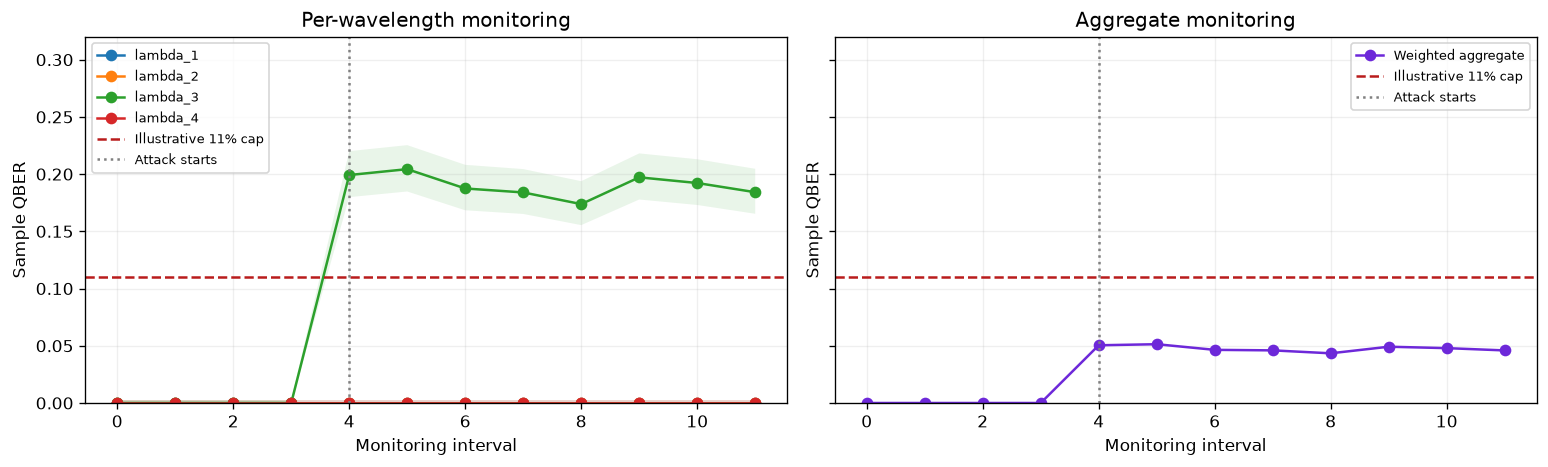

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for channel, group in telemetry.groupby('channel'):
    axes[0].plot(group.interval, group.qber, 'o-', label=channel)
    axes[0].fill_between(group.interval, group.qber_low, group.qber_high, alpha=0.10)
axes[1].plot(aggregate.interval, aggregate.qber, 'o-', color='#6d28d9', label='Weighted aggregate')
for ax in axes:
    ax.axhline(0.11, color='#b91c1c', linestyle='--', label='Illustrative 11% cap')
    ax.axvline(ATTACK_START, color='gray', linestyle=':', label='Attack starts')
    ax.set(xlabel='Monitoring interval', ylabel='Sample QBER', ylim=(0, 0.32))
    ax.grid(alpha=0.2); ax.legend(fontsize=8)
axes[0].set_title('Per-wavelength monitoring')
axes[1].set_title('Aggregate monitoring')
fig.tight_layout()
RESULTS = Path('results/notebook')
RESULTS.mkdir(parents=True, exist_ok=True)
fig.savefig(RESULTS/'wavelength_attack.png', dpi=160)
plt.show()
telemetry.to_csv(RESULTS/'telemetry.csv', index=False)
ground_truth.to_csv(RESULTS/'ground_truth.csv', index=False)
aggregate.to_csv(RESULTS/'aggregate.csv', index=False)
sweep_df.to_csv(RESULTS/'interception_sweep.csv', index=False)
print('Saved results to', RESULTS.resolve())


## 7. Next experiments

1. Change `ATTACK_FRACTION` to 0.2: expected lambda_3 QBER is only 5%, so the fixed 11% per-channel rule can also miss it.
2. Set independent channel error probabilities and compare confidence intervals against a measured healthy baseline.
3. Repeat with multiple seeds before claiming a detection rate.
4. Feed only `telemetry` to the statistical controller; use `ground_truth` only for scoring.
5. Integrate the companion optical/decoy model before reporting SKR. No SKR is inferred from unrevealed-bit count here.

References: [Qiskit AerSimulator](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html), [Aer noise models](https://qiskit.github.io/qiskit-aer/apidocs/aer_noise), [Ma et al., practical decoy-state QKD](https://arxiv.org/abs/quant-ph/0503005).
